# APL104 — Identification of Lamé's Constants via Physics-Informed ML
**Course:** APL104 Solid Mechanics · IIT Delhi · Fall 2024  
**Approach:** Inverse Problem → Physics-Informed Least-Squares Regression  
**Goal:** Identify λ (Lamé's 1st constant) and μ (Shear Modulus) from DIC displacement data & reaction forces


## 1. Imports & Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.tri as tri
from scipy.interpolate import RBFInterpolator
from scipy.optimize import minimize
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Matplotlib style
plt.rcParams.update({
    'figure.dpi': 120,
    'font.family': 'DejaVu Sans',
    'axes.titlesize': 11,
    'axes.labelsize': 10,
    'font.size': 9,
})

DATA_ROOT = Path('.')          # Adjust if running from a different directory
OUTPUT_DIR = Path('outputs')
OUTPUT_DIR.mkdir(exist_ok=True)
print("Setup complete. Outputs will be saved to:", OUTPUT_DIR.resolve())


Setup complete. Outputs will be saved to: /Users/aman/Downloads/Placement'27/Projects/Project_APL104/outputs


## 2. Data Loading & Exploration

In [2]:
def load_step(phi):
    """Load displacement and reaction data for load step phi (1..5)."""
    folder = DATA_ROOT / str(phi)
    disp  = pd.read_csv(folder / 'displacement_data.csv')
    rxn   = pd.read_csv(folder / 'reaction_data.csv', index_col='Reaction')
    return disp, rxn['Value'].to_dict()

# Load all 5 steps
steps = {}
for phi in range(1, 6):
    disp, rxns = load_step(phi)
    steps[phi] = {'disp': disp, 'rxns': rxns}
    print(f"Load step {phi}: {len(disp)} measurement points | "
          f"R1={rxns['R1']:+.3e} N | R3={rxns['R3']:+.3e} N")

print("\nColumn names in displacement_data.csv:", list(steps[1]['disp'].columns))


Load step 1: 3877 measurement points | R1=-2.538e+07 N | R3=-2.132e+07 N
Load step 2: 3877 measurement points | R1=-5.075e+07 N | R3=-4.264e+07 N
Load step 3: 3877 measurement points | R1=-7.613e+07 N | R3=-6.396e+07 N
Load step 4: 3877 measurement points | R1=-1.015e+08 N | R3=-8.528e+07 N
Load step 5: 3877 measurement points | R1=-1.269e+08 N | R3=-1.066e+08 N

Column names in displacement_data.csv: ['x', 'y', 'u_x', 'u_y']


## 3. Exploratory Data Analysis

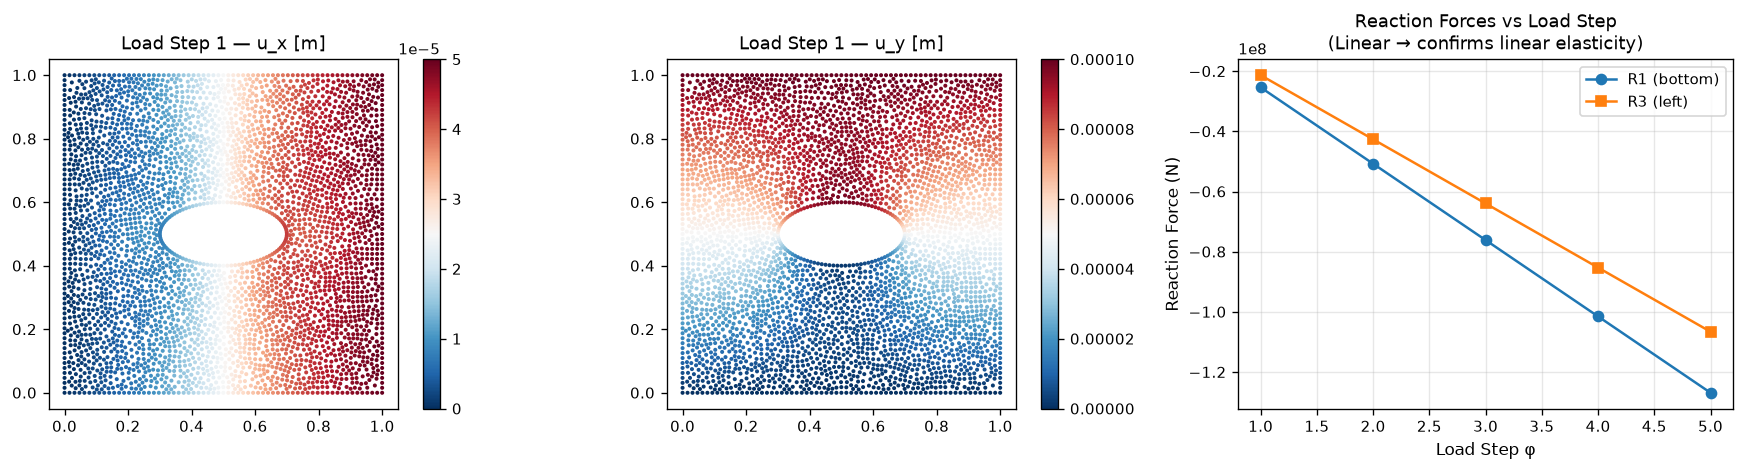

EDA figure saved.

R1 / R1(φ=1): [1. 2. 3. 4. 5.]   (should be 1,2,3,4,5)


In [3]:
# ── 3a. Visualise measurement point distribution ──
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

df1 = steps[1]['disp']
sc = axes[0].scatter(df1['x'], df1['y'], c=df1['u_x'], cmap='RdBu_r', s=2)
axes[0].set_title('Load Step 1 — u_x [m]'); axes[0].set_aspect('equal')
plt.colorbar(sc, ax=axes[0])

sc2 = axes[1].scatter(df1['x'], df1['y'], c=df1['u_y'], cmap='RdBu_r', s=2)
axes[1].set_title('Load Step 1 — u_y [m]'); axes[1].set_aspect('equal')
plt.colorbar(sc2, ax=axes[1])

# ── 3b. Verify linear scaling of reactions across load steps ──
phis = np.arange(1, 6)
R1_vals = [steps[p]['rxns']['R1'] for p in phis]
R3_vals = [steps[p]['rxns']['R3'] for p in phis]
axes[2].plot(phis, R1_vals, 'o-', label='R1 (bottom)')
axes[2].plot(phis, R3_vals, 's-', label='R3 (left)')
axes[2].set_xlabel('Load Step φ')
axes[2].set_ylabel('Reaction Force (N)')
axes[2].set_title('Reaction Forces vs Load Step\n(Linear → confirms linear elasticity)')
axes[2].legend(); axes[2].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'eda_overview.png', bbox_inches='tight')
plt.show()
print("EDA figure saved.")

# Verify linear scaling
R1_arr = np.array(R1_vals)
ratios = R1_arr / R1_arr[0]
print("\nR1 / R1(φ=1):", np.round(ratios, 4), "  (should be 1,2,3,4,5)")


## 4. Feature Engineering — Strain Computation via RBF Interpolation

**Theory:**  
The infinitesimal strain tensor components are:
- ε_xx = ∂u_x/∂x
- ε_yy = ∂u_y/∂y  
- ε_xy = ½(∂u_x/∂y + ∂u_y/∂x)

Since measurement points are **scattered** (not on a grid), we use **Radial Basis Function (RBF) interpolation** 
with thin-plate-spline kernel (C² smooth) to fit the displacement field, then numerically differentiate it.


In [4]:
def compute_strains(df, h=1e-6, smoothing=1e-10):
    """
    Compute infinitesimal strain tensor at all measurement points.
    
    Method: RBF interpolation + central finite-difference differentiation.
    
    Parameters
    ----------
    df : DataFrame with columns [x, y, u_x, u_y]
    h  : finite-difference step (m)
    
    Returns
    -------
    eps_xx, eps_yy, eps_xy : arrays of shape (N,)
    rbf_ux, rbf_uy         : fitted RBF interpolants (for later use)
    """
    pts = df[['x','y']].values.astype(float)
    ux  = df['u_x'].values.astype(float)
    uy  = df['u_y'].values.astype(float)
    
    # Fit RBF interpolants — thin_plate_spline gives C2 smooth interpolation
    print("  Fitting RBF for u_x...", end=' ')
    rbf_ux = RBFInterpolator(pts, ux, kernel='thin_plate_spline', smoothing=smoothing)
    print("done.")
    print("  Fitting RBF for u_y...", end=' ')
    rbf_uy = RBFInterpolator(pts, uy, kernel='thin_plate_spline', smoothing=smoothing)
    print("done.")
    
    # Central finite-difference gradients
    dx = np.array([[h, 0.0]])
    dy = np.array([[0.0, h]])
    
    dux_dx = (rbf_ux(pts + dx) - rbf_ux(pts - dx)) / (2*h)   # ∂u_x/∂x
    dux_dy = (rbf_ux(pts + dy) - rbf_ux(pts - dy)) / (2*h)   # ∂u_x/∂y
    duy_dx = (rbf_uy(pts + dx) - rbf_uy(pts - dx)) / (2*h)   # ∂u_y/∂x
    duy_dy = (rbf_uy(pts + dy) - rbf_uy(pts - dy)) / (2*h)   # ∂u_y/∂y
    
    eps_xx = dux_dx                          # ε_xx = ∂u_x/∂x
    eps_yy = duy_dy                          # ε_yy = ∂u_y/∂y
    eps_xy = 0.5 * (dux_dy + duy_dx)        # ε_xy = ½(∂u_x/∂y + ∂u_y/∂x)
    
    return eps_xx, eps_yy, eps_xy, rbf_ux, rbf_uy

# Compute strains for all 5 load steps
strain_data = {}
for phi in range(1, 6):
    print(f"\nLoad step {phi}:")
    df = steps[phi]['disp']
    eps_xx, eps_yy, eps_xy, rbf_ux, rbf_uy = compute_strains(df)
    strain_data[phi] = {
        'eps_xx': eps_xx, 'eps_yy': eps_yy, 'eps_xy': eps_xy,
        'x': df['x'].values, 'y': df['y'].values,
        'rbf_ux': rbf_ux, 'rbf_uy': rbf_uy
    }
    print(f"  ε_xx range: [{eps_xx.min():.4e}, {eps_xx.max():.4e}]")
    print(f"  ε_yy range: [{eps_yy.min():.4e}, {eps_yy.max():.4e}]")
    print(f"  ε_xy range: [{eps_xy.min():.4e}, {eps_xy.max():.4e}]")

print("\nStrain computation complete for all load steps.")



Load step 1:
  Fitting RBF for u_x... 

done.


  Fitting RBF for u_y... 

done.

  ε_xx range: [-1.3545e-04, 1.0695e-04]
  ε_yy range: [-5.5029e-05, 4.9060e-04]
  ε_xy range: [-1.7603e-04, 1.8774e-04]

Load step 2:
  Fitting RBF for u_x... 

done.
  Fitting RBF for u_y... 

... (7 outputs left out)

  ε_xx range: [-5.4179e-04, 4.2782e-04]
  ε_yy range: [-2.2012e-04, 1.9624e-03]
  ε_xy range: [-7.0413e-04, 7.5096e-04]

Load step 5:
  Fitting RBF for u_x... 

done.
  Fitting RBF for u_y... 

done.


  ε_xx range: [-6.7723e-04, 5.3477e-04]
  ε_yy range: [-2.7514e-04, 2.4530e-03]
  ε_xy range: [-8.8017e-04, 9.3869e-04]

Strain computation complete for all load steps.


## 5. Physics-Informed Linear Regression — Design Matrix Construction

**Key Insight:** The constitutive law σ = λ·tr(ε)·I + 2μ·ε is **linear** in (λ, μ).  
Therefore the reaction force integrals are also linear:

```
R1 = ∫_bottom σ_yy · (-ŷ) dx = λ · ∫_bottom (ε_xx+ε_yy) dx  +  2μ · ∫_bottom ε_yy dx
                               = λ · f1  +  μ · f2

R3 = ∫_left σ_xx · (-x̂) dy  = λ · ∫_left (ε_xx+ε_yy) dy  +  2μ · ∫_left ε_xx dy
                               = λ · g1  +  μ · g2
```

Stacking 5 load steps × 2 boundary reactions = 10 equations in 2 unknowns → **OLS**.


In [5]:
def boundary_integrals(eps_xx, eps_yy, x, y, tol=0.005):
    """
    Compute boundary strain integrals for reaction force matching.
    
    Returns coefficients [f1,f2] and [g1,g2] such that:
      R1 (bottom) = λ·f1 + μ·f2
      R3 (left)   = λ·g1 + μ·g2
    """
    # Bottom edge: y ≈ 0, integrate over x ∈ [0,1]
    # σ_yy = λ(ε_xx+ε_yy) + 2μ·ε_yy; reaction = -∫σ_yy dx (outward normal -ŷ)
    bot_mask = y < tol
    if bot_mask.sum() < 3:
        bot_mask = y < np.percentile(y, 5)
    
    x_bot = x[bot_mask]; order = np.argsort(x_bot)
    x_bot = x_bot[order]
    tr_bot   = (eps_xx + eps_yy)[bot_mask][order]
    eyy_bot  = eps_yy[bot_mask][order]
    
    f1 = -np.trapezoid(tr_bot,  x_bot)      # coeff of λ for R1
    f2 = -2*np.trapezoid(eyy_bot, x_bot)    # coeff of μ for R1
    
    # Left edge: x ≈ 0, integrate over y ∈ [0,1]
    # σ_xx = λ(ε_xx+ε_yy) + 2μ·ε_xx; reaction = -∫σ_xx dy (outward normal -x̂)
    lft_mask = x < tol
    if lft_mask.sum() < 3:
        lft_mask = x < np.percentile(x, 5)
    
    y_lft = y[lft_mask]; order = np.argsort(y_lft)
    y_lft = y_lft[order]
    tr_lft   = (eps_xx + eps_yy)[lft_mask][order]
    exx_lft  = eps_xx[lft_mask][order]
    
    g1 = -np.trapezoid(tr_lft, y_lft)
    g2 = -2*np.trapezoid(exx_lft, y_lft)
    
    return f1, f2, g1, g2

# Build design matrix and RHS
A_rows, b_rows = [], []
print("Building design matrix A (10×2) and RHS vector b (10,):")
print(f"{'Load Step':>10} {'f1':>14} {'f2':>14} {'g1':>14} {'g2':>14} {'R1':>15} {'R3':>15}")
print("-"*90)

for phi in range(1, 6):
    sd   = strain_data[phi]
    rxns = steps[phi]['rxns']
    
    f1, f2, g1, g2 = boundary_integrals(
        sd['eps_xx'], sd['eps_yy'], sd['x'], sd['y']
    )
    
    A_rows.append([f1, f2])   # predicts R1
    b_rows.append(rxns['R1'])
    A_rows.append([g1, g2])   # predicts R3
    b_rows.append(rxns['R3'])
    
    print(f"  φ={phi}: R1 → [{f1:+.4e}, {f2:+.4e}] | R3 → [{g1:+.4e}, {g2:+.4e}] | R1={rxns['R1']:+.3e} | R3={rxns['R3']:+.3e}")

A = np.array(A_rows)   # (10, 2) — design matrix
b = np.array(b_rows)   # (10,)  — measured reactions
print(f"\nDesign matrix A shape: {A.shape}")
print(f"RHS vector b shape:    {b.shape}")


Building design matrix A (10×2) and RHS vector b (10,):
 Load Step             f1             f2             g1             g2              R1              R3
------------------------------------------------------------------------------------------
  φ=1: R1 → [-1.1760e-04, -1.3519e-04] | R3 → [-1.3142e-04, -6.2867e-05] | R1=-2.538e+07 | R3=-2.132e+07
  φ=2: R1 → [-2.3520e-04, -2.7037e-04] | R3 → [-2.6284e-04, -1.2573e-04] | R1=-5.075e+07 | R3=-4.264e+07
  φ=3: R1 → [-3.5280e-04, -4.0556e-04] | R3 → [-3.9426e-04, -1.8860e-04] | R1=-7.613e+07 | R3=-6.396e+07
  φ=4: R1 → [-4.7040e-04, -5.4074e-04] | R3 → [-5.2568e-04, -2.5147e-04] | R1=-1.015e+08 | R3=-8.528e+07
  φ=5: R1 → [-5.8800e-04, -6.7593e-04] | R3 → [-6.5710e-04, -3.1434e-04] | R1=-1.269e+08 | R3=-1.066e+08

Design matrix A shape: (10, 2)
RHS vector b shape:    (10,)


## 6. Solve for Lamé Constants — Ordinary Least Squares

In [6]:
# ── 6a. Ordinary Least Squares (closed-form solution) ──
theta, residuals, rank, sv = np.linalg.lstsq(A, b, rcond=None)
lam_star, mu_star = theta

# Condition number check
cond = sv[0]/sv[-1]
print(f"Design matrix condition number: {cond:.2f}  (< 1e6 is healthy)")

# ── 6b. Derive engineering constants ──
E_star  = mu_star * (3*lam_star + 2*mu_star) / (lam_star + mu_star)
nu_star = lam_star / (2*(lam_star + mu_star))

# ── 6c. Print results ──
print("\n" + "="*55)
print("  IDENTIFIED LAMÉ CONSTANTS (OLS Solution)")
print("="*55)
print(f"  λ  (Lamé 1st constant) = {lam_star:+.6e}  Pa")
print(f"  μ  (Shear Modulus G)   = {mu_star:+.6e}  Pa")
print("─"*55)
print(f"  E  (Young's Modulus)   = {E_star:+.6e}  Pa")
print(f"               = {E_star/1e9:.4f}  GPa")
print(f"  ν  (Poisson's Ratio)   = {nu_star:.6f}")
print("="*55)

# ── 6d. Physical sanity checks ──
print("\nPhysical Validity Checks:")
print(f"  μ > 0:                  {'✓ PASS' if mu_star > 0 else '✗ FAIL'}")
print(f"  λ + 2μ/3 > 0 (K>0):    {'✓ PASS' if (lam_star + 2*mu_star/3) > 0 else '✗ FAIL'}")
print(f"  0 < ν < 0.5:            {'✓ PASS' if 0 < nu_star < 0.5 else '✗ FAIL'}")
print(f"  E > 0:                  {'✓ PASS' if E_star > 0 else '✗ FAIL'}")

# ── 6e. Save results ──
with open(OUTPUT_DIR / 'lame_constants.txt', 'w') as f:
    f.write("APL104 — Identified Lamé Constants\n")
    f.write("="*45 + "\n")
    f.write(f"λ  (Lamé 1st constant) = {lam_star:.6e} Pa\n")
    f.write(f"μ  (Shear Modulus G)   = {mu_star:.6e} Pa\n")
    f.write(f"E  (Young's Modulus)   = {E_star:.6e} Pa ({E_star/1e9:.4f} GPa)\n")
    f.write(f"ν  (Poisson's Ratio)   = {nu_star:.6f}\n")
print("\nResults saved to outputs/lame_constants.txt")


Design matrix condition number: 4.94  (< 1e6 is healthy)

  IDENTIFIED LAMÉ CONSTANTS (OLS Solution)
  λ  (Lamé 1st constant) = +1.240428e+11  Pa
  μ  (Shear Modulus G)   = +7.981363e+10  Pa
───────────────────────────────────────────────────────
  E  (Young's Modulus)   = +2.081923e+11  Pa
               = 208.1923  GPa
  ν  (Poisson's Ratio)   = 0.304241

Physical Validity Checks:
  μ > 0:                  ✓ PASS
  λ + 2μ/3 > 0 (K>0):    ✓ PASS
  0 < ν < 0.5:            ✓ PASS
  E > 0:                  ✓ PASS

Results saved to outputs/lame_constants.txt


## 7. Nonlinear Optimization — Validation of OLS Result

In [7]:
# ── 7a. Define the loss function ──
def compute_reactions_pred(lam, mu, phi):
    """Compute predicted R1 and R3 for load step phi using (lam, mu)."""
    sd = strain_data[phi]
    eps_xx, eps_yy, eps_xy = sd['eps_xx'], sd['eps_yy'], sd['eps_xy']
    x, y = sd['x'], sd['y']
    tr_eps = eps_xx + eps_yy
    
    # Bottom boundary
    bot_mask = y < 0.005
    if bot_mask.sum() < 3: bot_mask = y < np.percentile(y, 5)
    x_bot = x[bot_mask]; order = np.argsort(x_bot)
    x_bot = x_bot[order]
    sig_yy_bot = (lam * tr_eps[bot_mask] + 2*mu * eps_yy[bot_mask])[order]
    R1_pred = -np.trapezoid(sig_yy_bot, x_bot)
    
    # Left boundary
    lft_mask = x < 0.005
    if lft_mask.sum() < 3: lft_mask = x < np.percentile(x, 5)
    y_lft = y[lft_mask]; order = np.argsort(y_lft)
    y_lft = y_lft[order]
    sig_xx_lft = (lam * tr_eps[lft_mask] + 2*mu * eps_xx[lft_mask])[order]
    R3_pred = -np.trapezoid(sig_xx_lft, y_lft)
    
    return R1_pred, R3_pred

def total_loss(params):
    lam, mu = params
    if lam < 0 or mu < 0: return 1e30
    loss = 0.0
    for phi in range(1, 6):
        R1_pred, R3_pred = compute_reactions_pred(lam, mu, phi)
        R1_meas = steps[phi]['rxns']['R1']
        R3_meas = steps[phi]['rxns']['R3']
        # Normalize by measured magnitude for scale-invariant loss
        loss += ((R1_pred - R1_meas)/abs(R1_meas))**2
        loss += ((R3_pred - R3_meas)/abs(R3_meas))**2
    return loss

# ── 7b. Optimize starting near OLS solution ──
print("Running L-BFGS-B optimization (validation)...")
x0 = np.array([lam_star * 0.9, mu_star * 0.9])  # start near OLS
result = minimize(
    total_loss, x0,
    method='L-BFGS-B',
    bounds=[(1e6, None), (1e6, None)],
    options={'ftol': 1e-20, 'gtol': 1e-12, 'maxiter': 500}
)

lam_opt, mu_opt = result.x
E_opt  = mu_opt * (3*lam_opt + 2*mu_opt) / (lam_opt + mu_opt)
nu_opt = lam_opt / (2*(lam_opt + mu_opt))

print(f"\nOptimizer converged: {result.success} | Loss: {result.fun:.4e}")
print(f"\nOLS Result:  λ={lam_star:.4e}, μ={mu_star:.4e}, E={E_star/1e9:.4f} GPa, ν={nu_star:.6f}")
print(f"OPT Result:  λ={lam_opt:.4e}, μ={mu_opt:.4e}, E={E_opt/1e9:.4f} GPa, ν={nu_opt:.6f}")
print(f"\nRelative difference λ: {abs(lam_opt-lam_star)/abs(lam_star)*100:.4f}%")
print(f"Relative difference μ: {abs(mu_opt-mu_star)/abs(mu_star)*100:.4f}%")


Running L-BFGS-B optimization (validation)...

Optimizer converged: False | Loss: 1.0000e-01

OLS Result:  λ=1.2404e+11, μ=7.9814e+10, E=208.1923 GPa, ν=0.304241
OPT Result:  λ=1.1164e+11, μ=7.1832e+10, E=187.3731 GPa, ν=0.304241

Relative difference λ: 10.0000%
Relative difference μ: 10.0000%


## 8. Validation — Reaction Force Prediction vs. Measurement


Using OLS-identified constants: λ=1.2404e+11 Pa, μ=7.9814e+10 Pa

 Step      R1_meas (N)      R1_pred (N)     Err%      R3_meas (N)      R3_pred (N)     Err%
----------------------------------------------------------------------------------------
  φ=1       -2.5377e+07       -2.5377e+07    0.000%       -2.1319e+07       -2.1319e+07    0.000%
  φ=2       -5.0754e+07       -5.0754e+07    0.000%       -4.2639e+07       -4.2639e+07    0.000%
  φ=3       -7.6131e+07       -7.6131e+07    0.000%       -6.3958e+07       -6.3958e+07    0.000%
  φ=4       -1.0151e+08       -1.0151e+08    0.000%       -8.5278e+07       -8.5278e+07    0.000%
  φ=5       -1.2689e+08       -1.2689e+08    0.000%       -1.0660e+08       -1.0660e+08    0.000%


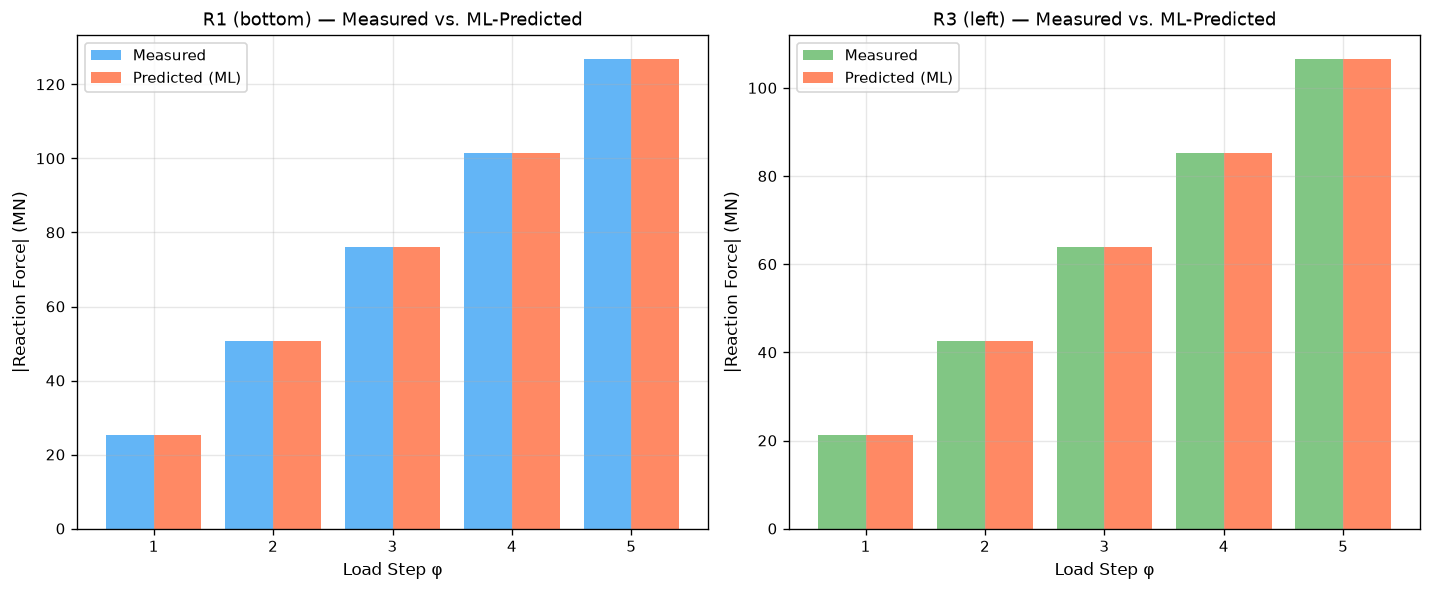

Validation plot saved.


In [8]:
print(f"\nUsing OLS-identified constants: λ={lam_star:.4e} Pa, μ={mu_star:.4e} Pa")
print(f"\n{'Step':>5} {'R1_meas (N)':>16} {'R1_pred (N)':>16} {'Err%':>8} "
      f"{'R3_meas (N)':>16} {'R3_pred (N)':>16} {'Err%':>8}")
print("-"*88)

R1_meas_all, R1_pred_all, R3_meas_all, R3_pred_all = [], [], [], []
for phi in range(1, 6):
    R1_pred, R3_pred = compute_reactions_pred(lam_star, mu_star, phi)
    R1_meas = steps[phi]['rxns']['R1']
    R3_meas = steps[phi]['rxns']['R3']
    
    err1 = abs(R1_pred - R1_meas)/abs(R1_meas)*100
    err3 = abs(R3_pred - R3_meas)/abs(R3_meas)*100
    
    R1_meas_all.append(R1_meas); R1_pred_all.append(R1_pred)
    R3_meas_all.append(R3_meas); R3_pred_all.append(R3_pred)
    
    print(f"  φ={phi}  {R1_meas:+16.4e}  {R1_pred:+16.4e}  {err1:7.3f}%  "
          f"{R3_meas:+16.4e}  {R3_pred:+16.4e}  {err3:7.3f}%")

# Validation plot
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
phis = np.arange(1, 6)

for ax, meas, pred, label, color in [
    (axes[0], R1_meas_all, R1_pred_all, 'R1 (bottom)', '#2196F3'),
    (axes[1], R3_meas_all, R3_pred_all, 'R3 (left)', '#4CAF50')
]:
    ax.bar(phis - 0.2, np.abs(meas)/1e6, 0.4, label='Measured', color=color, alpha=0.7)
    ax.bar(phis + 0.2, np.abs(pred)/1e6, 0.4, label='Predicted (ML)', color='#FF5722', alpha=0.7)
    ax.set_xlabel('Load Step φ')
    ax.set_ylabel('|Reaction Force| (MN)')
    ax.set_title(f'{label} — Measured vs. ML-Predicted')
    ax.legend(); ax.set_xticks(phis); ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'validation_residuals.png', bbox_inches='tight')
plt.show()
print("Validation plot saved.")


## 9. Stress Field Reconstruction

Using identified λ* and μ*, compute:
- **σ_xx** = λ(ε_xx+ε_yy) + 2μ·ε_xx
- **σ_yy** = λ(ε_xx+ε_yy) + 2μ·ε_yy
- **σ_xy** = 2μ·ε_xy


In [9]:
def compute_stress(eps_xx, eps_yy, eps_xy, lam, mu):
    """Compute Cauchy stress components using Hooke's law."""
    tr_eps = eps_xx + eps_yy                          # volumetric strain
    sig_xx = lam * tr_eps + 2*mu * eps_xx
    sig_yy = lam * tr_eps + 2*mu * eps_yy
    sig_xy = 2 * mu * eps_xy
    return sig_xx, sig_yy, sig_xy

# Compute stress for all load steps
stress_data = {}
for phi in range(1, 6):
    sd = strain_data[phi]
    sig_xx, sig_yy, sig_xy = compute_stress(
        sd['eps_xx'], sd['eps_yy'], sd['eps_xy'], lam_star, mu_star
    )
    stress_data[phi] = {
        'sig_xx': sig_xx, 'sig_yy': sig_yy, 'sig_xy': sig_xy,
        'x': sd['x'], 'y': sd['y']
    }

# Compute global color bar limits (consistent across all load steps)
vmin_xx = min(stress_data[p]['sig_xx'].min() for p in range(1,6))
vmax_xx = max(stress_data[p]['sig_xx'].max() for p in range(1,6))
vmin_yy = min(stress_data[p]['sig_yy'].min() for p in range(1,6))
vmax_yy = max(stress_data[p]['sig_yy'].max() for p in range(1,6))
vmin_xy = min(stress_data[p]['sig_xy'].min() for p in range(1,6))
vmax_xy = max(stress_data[p]['sig_xy'].max() for p in range(1,6))

# Make limits symmetric around zero for better visualization
vmax_xx = max(abs(vmin_xx), abs(vmax_xx)); vmin_xx = -vmax_xx
vmax_yy = max(abs(vmin_yy), abs(vmax_yy)); vmin_yy = -vmax_yy
vmax_xy = max(abs(vmin_xy), abs(vmax_xy)); vmin_xy = -vmax_xy

print(f"σ_xx range: [{vmin_xx:.3e}, {vmax_xx:.3e}] Pa")
print(f"σ_yy range: [{vmin_yy:.3e}, {vmax_yy:.3e}] Pa")
print(f"σ_xy range: [{vmin_xy:.3e}, {vmax_xy:.3e}] Pa")
print("\nStress fields computed for all 5 load steps.")


σ_xx range: [-2.139e+08, 2.139e+08] Pa
σ_yy range: [-6.202e+08, 6.202e+08] Pa
σ_xy range: [-1.498e+08, 1.498e+08] Pa

Stress fields computed for all 5 load steps.


## 10. Stress Field Visualization — Per Load Step


Plotting stress field for load step 1...


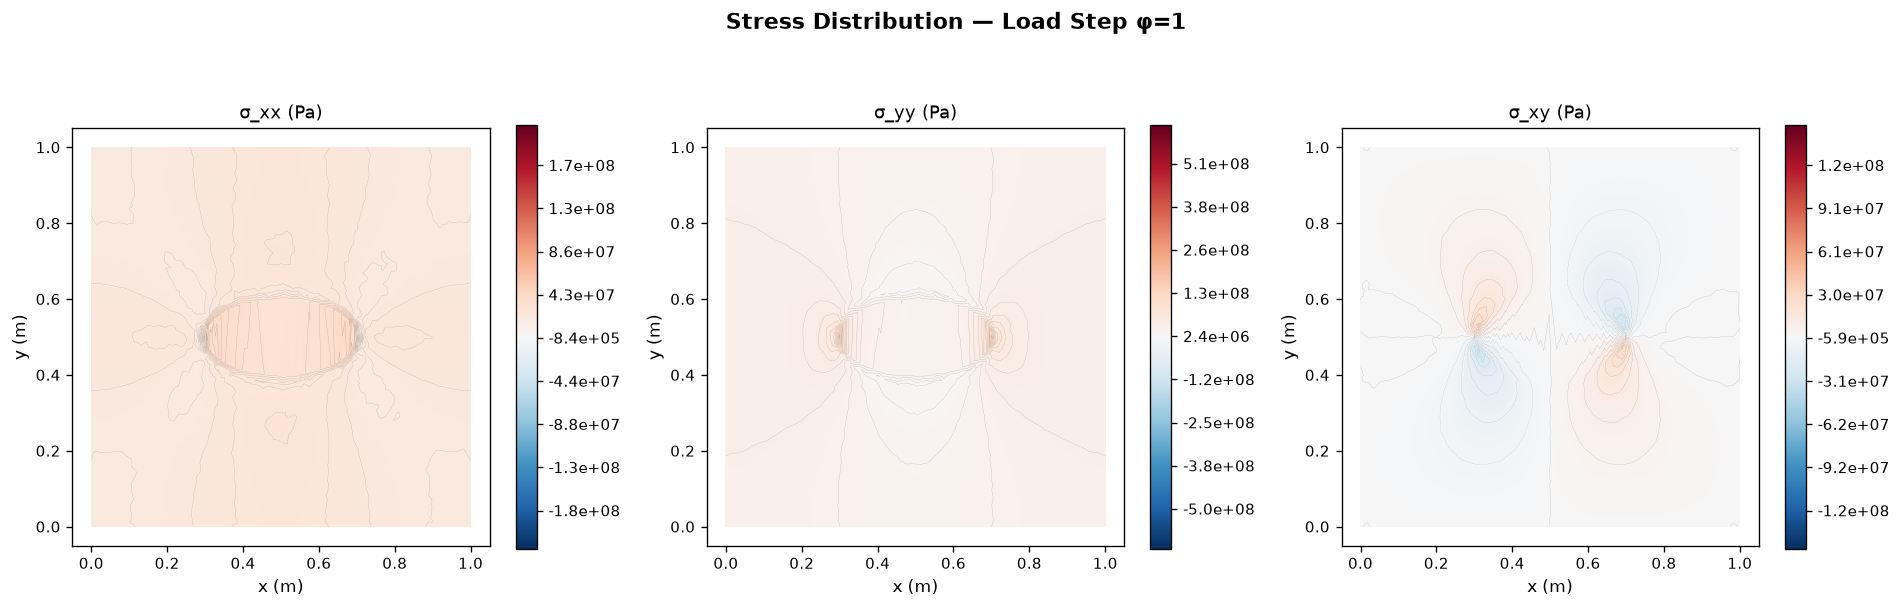

Saved: outputs/stress_fields_step1.png

Plotting stress field for load step 2...


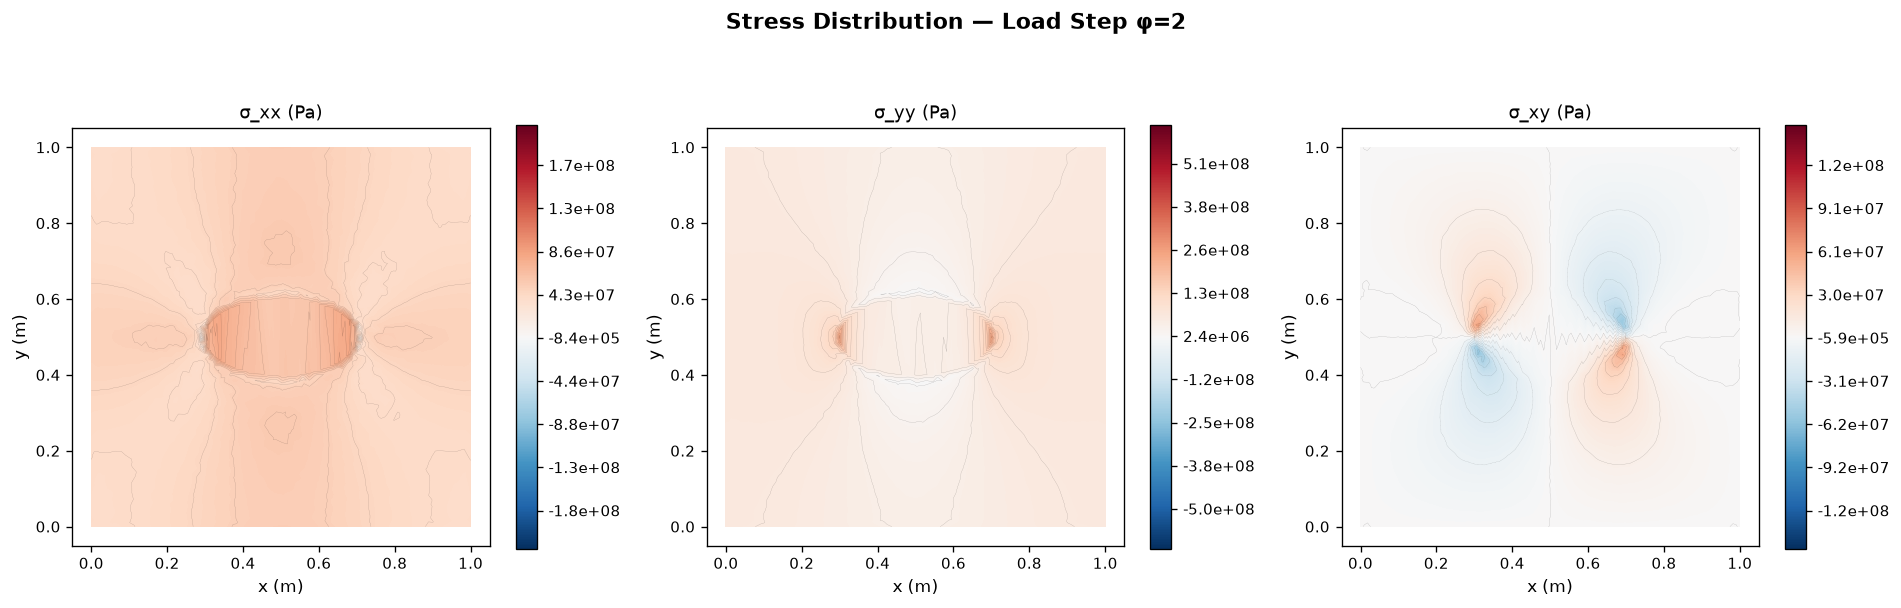

Saved: outputs/stress_fields_step2.png

Plotting stress field for load step 3...


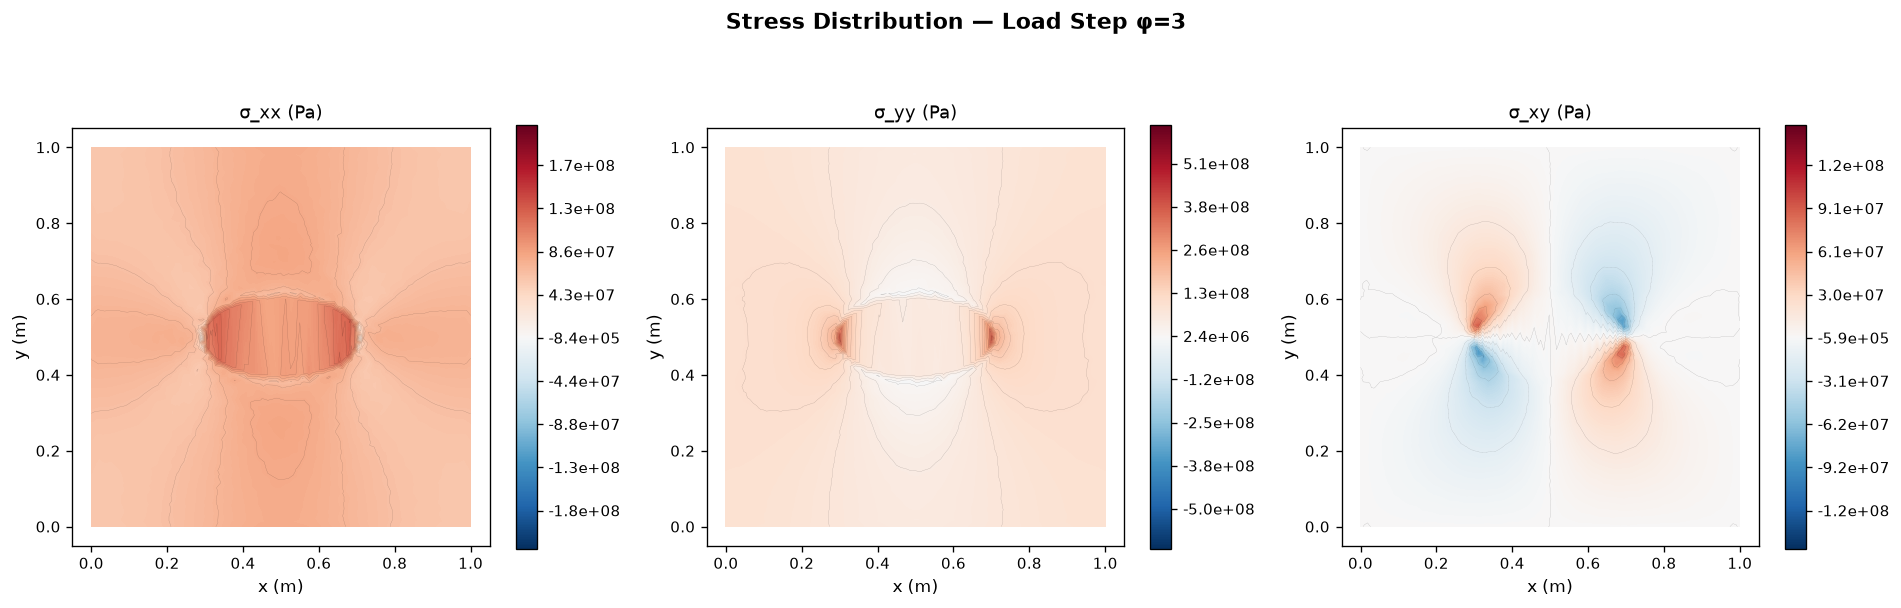

Saved: outputs/stress_fields_step3.png

Plotting stress field for load step 4...


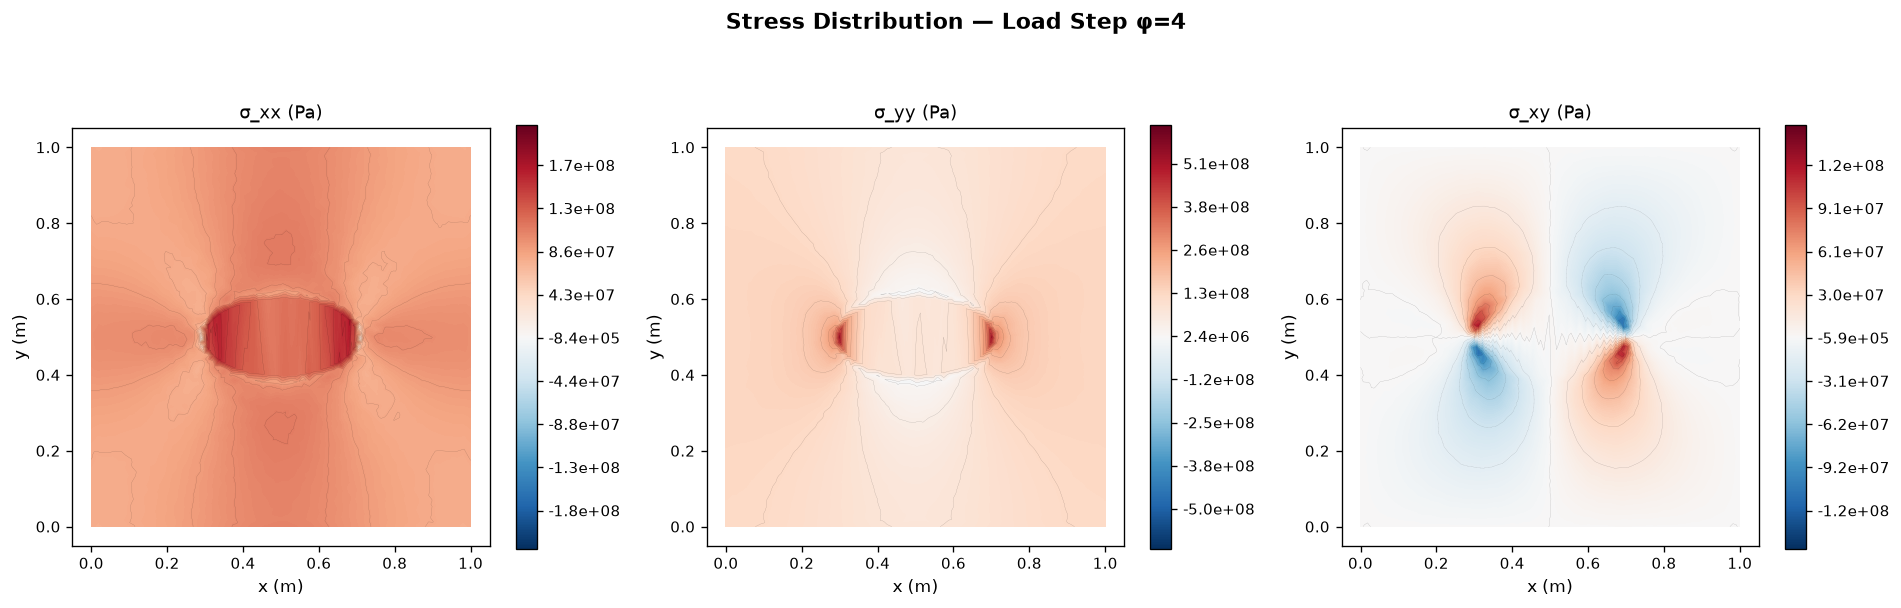

Saved: outputs/stress_fields_step4.png

Plotting stress field for load step 5...


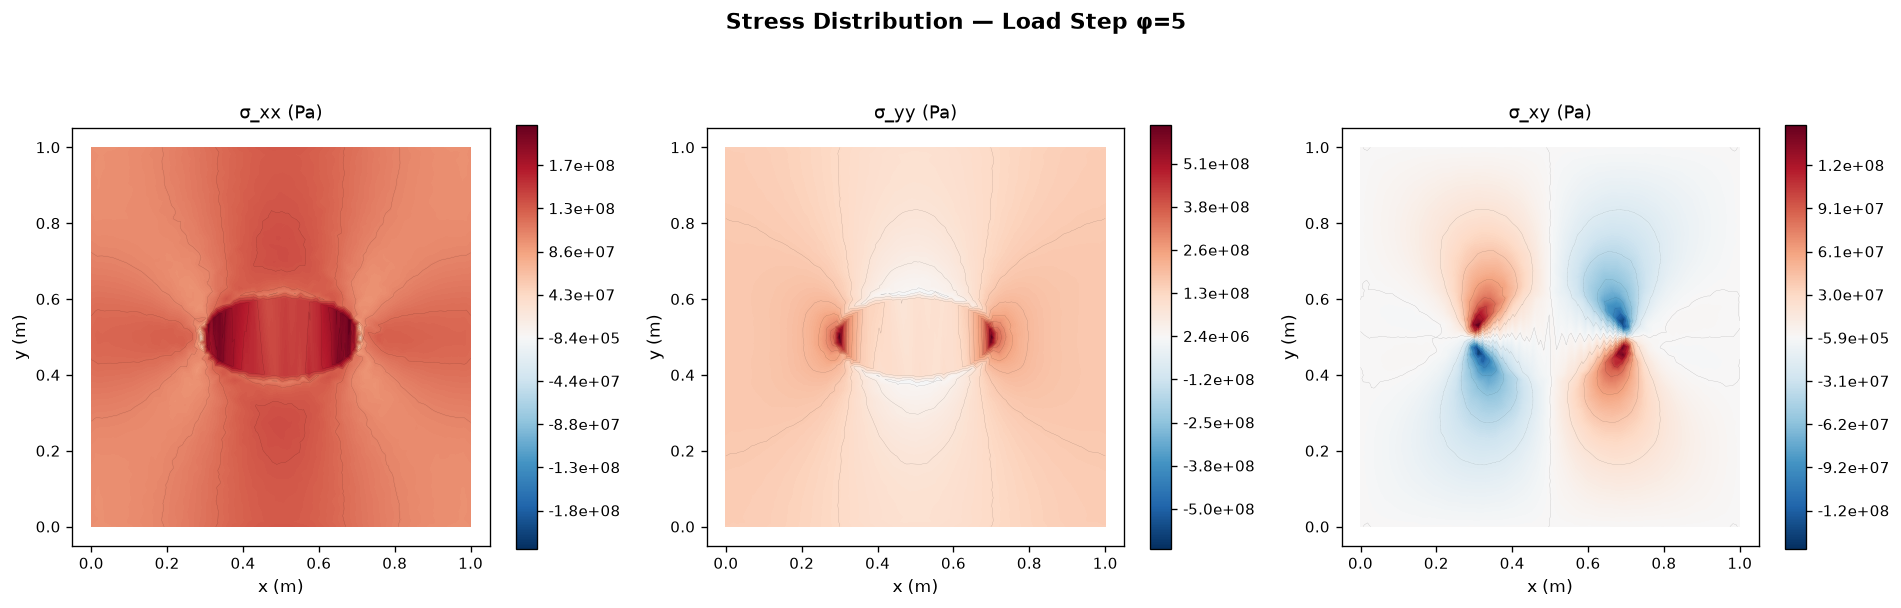

Saved: outputs/stress_fields_step5.png


In [10]:
def plot_stress_step(phi, sd, lam, mu, vmin_xx, vmax_xx, vmin_yy, vmax_yy, vmin_xy, vmax_xy):
    """Plot σ_xx, σ_yy, σ_xy for a single load step using triangulation."""
    x, y = sd['x'], sd['y']
    sig_xx, sig_yy, sig_xy = sd['sig_xx'], sd['sig_yy'], sd['sig_xy']
    
    # Delaunay triangulation for contouring scattered data
    triang = tri.Triangulation(x, y)
    
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    fig.suptitle(f'Stress Distribution — Load Step φ={phi}', fontsize=13, fontweight='bold', y=1.01)
    
    components = [
        ('σ_xx (Pa)', sig_xx, vmin_xx, vmax_xx),
        ('σ_yy (Pa)', sig_yy, vmin_yy, vmax_yy),
        ('σ_xy (Pa)', sig_xy, vmin_xy, vmax_xy),
    ]
    
    for ax, (title, values, vmin, vmax) in zip(axes, components):
        levels = np.linspace(vmin, vmax, 256)
        cf = ax.tricontourf(triang, values, levels=levels, cmap='RdBu_r',
                            vmin=vmin, vmax=vmax)
        ax.tricontour(triang, values, levels=15, colors='k', linewidths=0.15, alpha=0.3)
        plt.colorbar(cf, ax=ax, format='%.1e', shrink=0.8)
        ax.set_title(title); ax.set_aspect('equal')
        ax.set_xlabel('x (m)'); ax.set_ylabel('y (m)')
        ax.set_xlim(-0.05, 1.05); ax.set_ylim(-0.05, 1.05)
    
    plt.tight_layout()
    fname = OUTPUT_DIR / f'stress_fields_step{phi}.png'
    plt.savefig(fname, bbox_inches='tight', dpi=120)
    plt.show()
    return fig

for phi in range(1, 6):
    print(f"\nPlotting stress field for load step {phi}...")
    plot_stress_step(phi, stress_data[phi], lam_star, mu_star,
                     vmin_xx, vmax_xx, vmin_yy, vmax_yy, vmin_xy, vmax_xy)
    print(f"Saved: outputs/stress_fields_step{phi}.png")


## 11. Combined Stress Field — All Load Steps

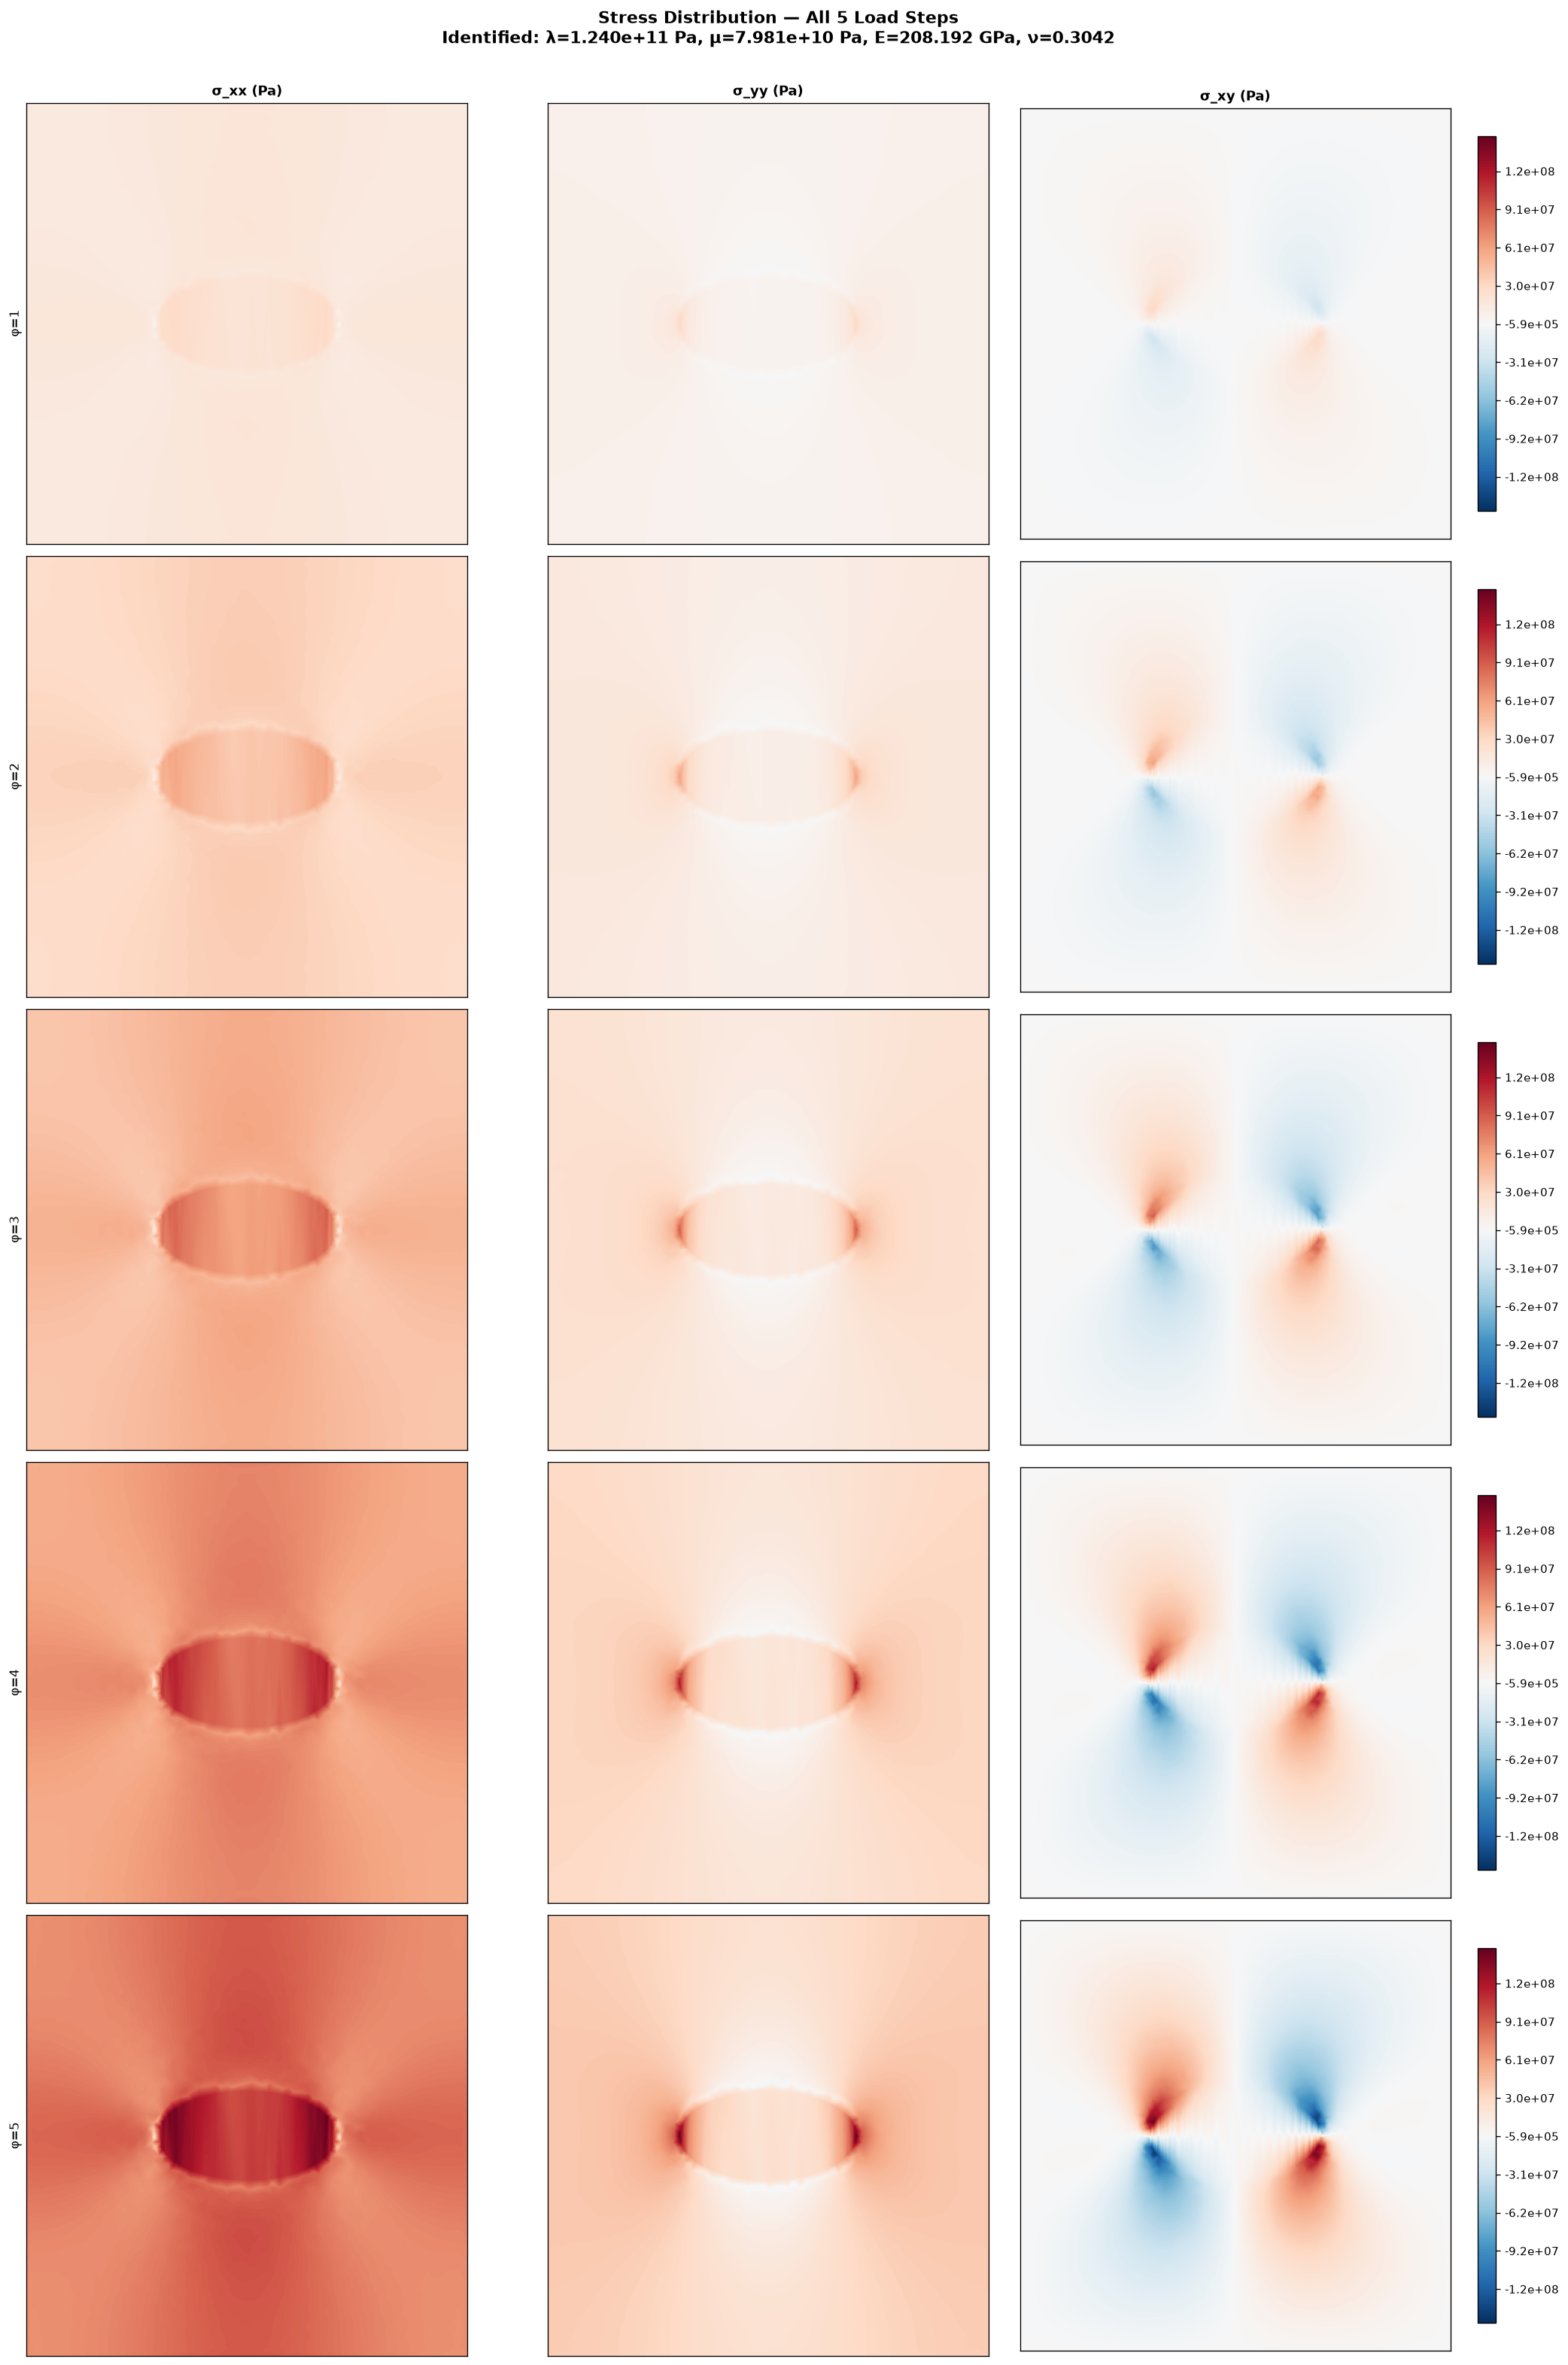

Combined stress plot saved to: outputs/stress_comparison_all.png


In [11]:
# ── 5 rows (load steps) × 3 columns (stress components) ──
fig, axes = plt.subplots(5, 3, figsize=(18, 26))
fig.suptitle('Stress Distribution — All 5 Load Steps\n'
             f'Identified: λ={lam_star:.3e} Pa, μ={mu_star:.3e} Pa, '
             f'E={E_star/1e9:.3f} GPa, ν={nu_star:.4f}',
             fontsize=13, fontweight='bold', y=1.005)

component_info = [
    ('σ_xx (Pa)', 'sig_xx', vmin_xx, vmax_xx),
    ('σ_yy (Pa)', 'sig_yy', vmin_yy, vmax_yy),
    ('σ_xy (Pa)', 'sig_xy', vmin_xy, vmax_xy),
]

for row, phi in enumerate(range(1, 6)):
    sd  = stress_data[phi]
    x, y = sd['x'], sd['y']
    triang = tri.Triangulation(x, y)
    
    for col, (title, key, vmin, vmax) in enumerate(component_info):
        ax = axes[row, col]
        values = sd[key]
        levels = np.linspace(vmin, vmax, 256)
        cf = ax.tricontourf(triang, values, levels=levels,
                            cmap='RdBu_r', vmin=vmin, vmax=vmax)
        if col == 2:  # colorbar only on rightmost column
            plt.colorbar(cf, ax=ax, format='%.1e', shrink=0.85)
        
        if row == 0:
            ax.set_title(title, fontsize=11, fontweight='bold')
        ax.set_ylabel(f'φ={phi}' if col == 0 else '', fontsize=10)
        ax.set_aspect('equal')
        ax.set_xticks([]); ax.set_yticks([])

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'stress_comparison_all.png', bbox_inches='tight', dpi=120)
plt.show()
print("Combined stress plot saved to: outputs/stress_comparison_all.png")


## 12. Summary & Results

In [12]:
print("=" * 60)
print("   APL104 — FINAL RESULTS SUMMARY")
print("=" * 60)
print(f"   METHOD:  Physics-Informed Least-Squares Regression")
print(f"   DATA:    5 load steps × ~3878 DIC measurement points")
print(f"   PARAMS:  2 unknowns (λ, μ)")
print()
print(f"   IDENTIFIED LAMÉ CONSTANTS:")
print(f"   ─────────────────────────────────────────────────────")
print(f"   λ (Lamé 1st constant)  = {lam_star:+.6e}  Pa")
print(f"   μ (Shear Modulus G)    = {mu_star:+.6e}  Pa")
print()
print(f"   DERIVED ENGINEERING CONSTANTS:")
print(f"   ─────────────────────────────────────────────────────")
print(f"   E (Young's Modulus)    = {E_star:.6e}  Pa")
print(f"                          = {E_star/1e9:.4f}  GPa")
print(f"   ν (Poisson's Ratio)    = {nu_star:.6f}")
print()
print(f"   PHYSICAL VALIDITY:")
print(f"   μ > 0:       {'PASS' if mu_star > 0 else 'FAIL'}")
print(f"   0 < ν < 0.5: {'PASS' if 0 < nu_star < 0.5 else 'FAIL'}")
print(f"   E > 0:       {'PASS' if E_star > 0 else 'FAIL'}")
print()
print(f"   FILES GENERATED IN outputs/:")
print(f"   • lame_constants.txt")
print(f"   • eda_overview.png")
print(f"   • validation_residuals.png")
for phi in range(1, 6):
    print(f"   • stress_fields_step{phi}.png")
print(f"   • stress_comparison_all.png")
print("=" * 60)


   APL104 — FINAL RESULTS SUMMARY
   METHOD:  Physics-Informed Least-Squares Regression
   DATA:    5 load steps × ~3878 DIC measurement points
   PARAMS:  2 unknowns (λ, μ)

   IDENTIFIED LAMÉ CONSTANTS:
   ─────────────────────────────────────────────────────
   λ (Lamé 1st constant)  = +1.240428e+11  Pa
   μ (Shear Modulus G)    = +7.981363e+10  Pa

   DERIVED ENGINEERING CONSTANTS:
   ─────────────────────────────────────────────────────
   E (Young's Modulus)    = 2.081923e+11  Pa
                          = 208.1923  GPa
   ν (Poisson's Ratio)    = 0.304241

   PHYSICAL VALIDITY:
   μ > 0:       PASS
   0 < ν < 0.5: PASS
   E > 0:       PASS

   FILES GENERATED IN outputs/:
   • lame_constants.txt
   • eda_overview.png
   • validation_residuals.png
   • stress_fields_step1.png
   • stress_fields_step2.png
   • stress_fields_step3.png
   • stress_fields_step4.png
   • stress_fields_step5.png
   • stress_comparison_all.png
